# Student Performance Analysis

**Goal:** explore what factors are associated with student outcomes, and build a model
to predict final grade (A–F) from study habits, attendance, sleep, and background features.

**Dataset:** `student_performance_dataset.csv` — 1000 students, 12 columns:

| Column | Description |
|---|---|
| `student_id` | Unique identifier |
| `gender` | Male / Female |
| `study_time_hours` | Weekly study hours |
| `attendance_percent` | Class attendance % |
| `sleep_hours` | Average nightly sleep |
| `parental_education` | Highest parental education level (has missing values) |
| `internet_access` | Yes/No |
| `extracurricular_activities` | Yes/No |
| `part_time_job` | Yes/No |
| `previous_grade` | Prior term score (0-100) |
| `final_exam_score` | Final exam score (0-100) |
| `final_grade` | Letter grade A-F (target) |

**Notebook structure:**
1. Setup & data loading
2. Data cleaning
3. Exploratory data analysis (distributions, correlations, categorical breakdowns)
4. Feature engineering & preprocessing
5. Modeling (baseline + tuned classifier)
6. Evaluation
7. Conclusion & next steps


# 1. Setup and data loading

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/harshadapatil31/student-performance-and-study-habits-dataset/student_performance_dataset.csv


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

RANDOM_STATE = 42

In [3]:
df = pd.read_csv("/kaggle/input/datasets/harshadapatil31/student-performance-and-study-habits-dataset/student_performance_dataset.csv")
print(df.shape)
df.head()

(1000, 12)


,student_id,gender,study_time_hours,attendance_percent,sleep_hours,parental_education,internet_access,extracurricular_activities,part_time_job,previous_grade,final_exam_score,final_grade
0,1,Male,4.0,98.0,6.5,Bachelors,Yes,Yes,No,76.9,100.0,A
1,2,Female,6.3,100.0,5.7,High School,Yes,Yes,Yes,75.5,100.0,A
2,3,Male,4.9,85.3,7.9,Bachelors,Yes,No,Yes,88.5,97.3,A
3,4,Male,2.6,77.5,8.0,NaN,Yes,Yes,No,85.1,83.8,B
4,5,Male,2.2,89.6,4.6,Bachelors,Yes,No,Yes,61.8,68.3,D


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   student_id                  1000 non-null   int64  
 1   gender                      1000 non-null   object 
 2   study_time_hours            1000 non-null   float64
 3   attendance_percent          1000 non-null   float64
 4   sleep_hours                 1000 non-null   float64
 5   parental_education          898 non-null    object 
 6   internet_access             1000 non-null   object 
 7   extracurricular_activities  1000 non-null   object 
 8   part_time_job               1000 non-null   object 
 9   previous_grade              1000 non-null   float64
 10  final_exam_score            1000 non-null   float64
 11  final_grade                 1000 non-null   object 
dtypes: float64(5), int64(1), object(6)
memory usage: 93.9+ KB


In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
student_id,1000.0,NaN,NaN,NaN,500.5,288.819436,1.0,250.75,500.5,750.25,1000.0
gender,1000,2,Female,510,NaN,NaN,NaN,NaN,NaN,NaN,NaN
study_time_hours,1000.0,NaN,NaN,NaN,3.5707,1.478559,0.5,2.6,3.6,4.5,8.1
attendance_percent,1000.0,NaN,NaN,NaN,85.0923,9.270685,54.8,78.8,85.2,91.9,100.0
sleep_hours,1000.0,NaN,NaN,NaN,6.7995,1.203527,3.2,5.9,6.8,7.6,10.0
parental_education,898,4,High School,356,NaN,NaN,NaN,NaN,NaN,NaN,NaN
internet_access,1000,2,Yes,854,NaN,NaN,NaN,NaN,NaN,NaN,NaN
extracurricular_activities,1000,2,Yes,572,NaN,NaN,NaN,NaN,NaN,NaN,NaN
part_time_job,1000,2,No,684,NaN,NaN,NaN,NaN,NaN,NaN,NaN
previous_grade,1000.0,NaN,NaN,NaN,69.7409,12.613425,31.3,61.0,69.6,78.4,100.0


# 2. Data Cleaning
`parental_education` has missing values. We'll check how many, then decide on an
imputation strategy (a dedicated `"Unknown"` category, since the missingness itself
may be informative rather than random).

In [6]:
df.isnull().sum().sort_values(ascending=False)

parental_education            102
student_id                      0
study_time_hours                0
gender                          0
attendance_percent              0
sleep_hours                     0
internet_access                 0
extracurricular_activities      0
part_time_job                   0
previous_grade                  0
final_exam_score                0
final_grade                     0
dtype: int64

In [7]:
df["parental_education"] = df["parental_education"].fillna("Unknown")

# sanity check for duplicates and obviously invalid ranges
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate student_id:", df["student_id"].duplicated().sum())
for col in ["study_time_hours", "attendance_percent", "sleep_hours", "previous_grade", "final_exam_score"]:
    print(f"{col}: min={df[col].min()}, max={df[col].max()}")

Duplicate rows: 0
Duplicate student_id: 0
study_time_hours: min=0.5, max=8.1
attendance_percent: min=54.8, max=100.0
sleep_hours: min=3.2, max=10.0
previous_grade: min=31.3, max=100.0
final_exam_score: min=46.8, max=100.0


# 3. Exploratory data analysis

### 3.1 Target Distribution

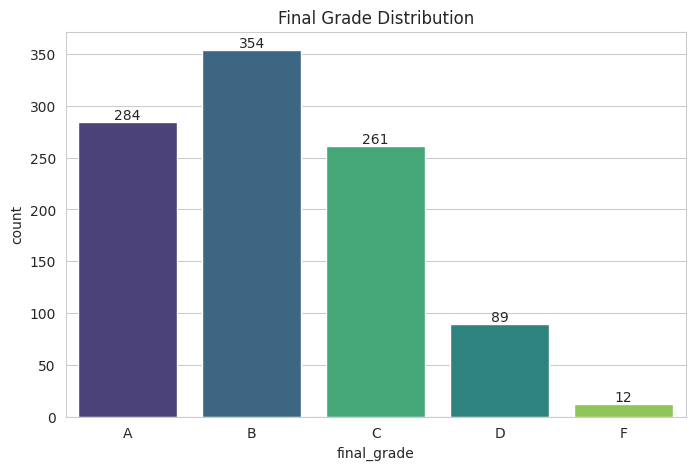

In [8]:
order = ["A", "B", "C", "D", "F"]

ax = sns.countplot(
    data=df, 
    x="final_grade", 
    hue="final_grade", 
    legend=False, 
    order=order, 
    palette="viridis"
)

ax.set_title("Final Grade Distribution")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom")
plt.show()

The classes are imbalanced (few `D`/`F` students), which we'll keep in mind when
choosing evaluation metrics accuracy alone would be misleading.

### 3.2 Numeric feature distributions

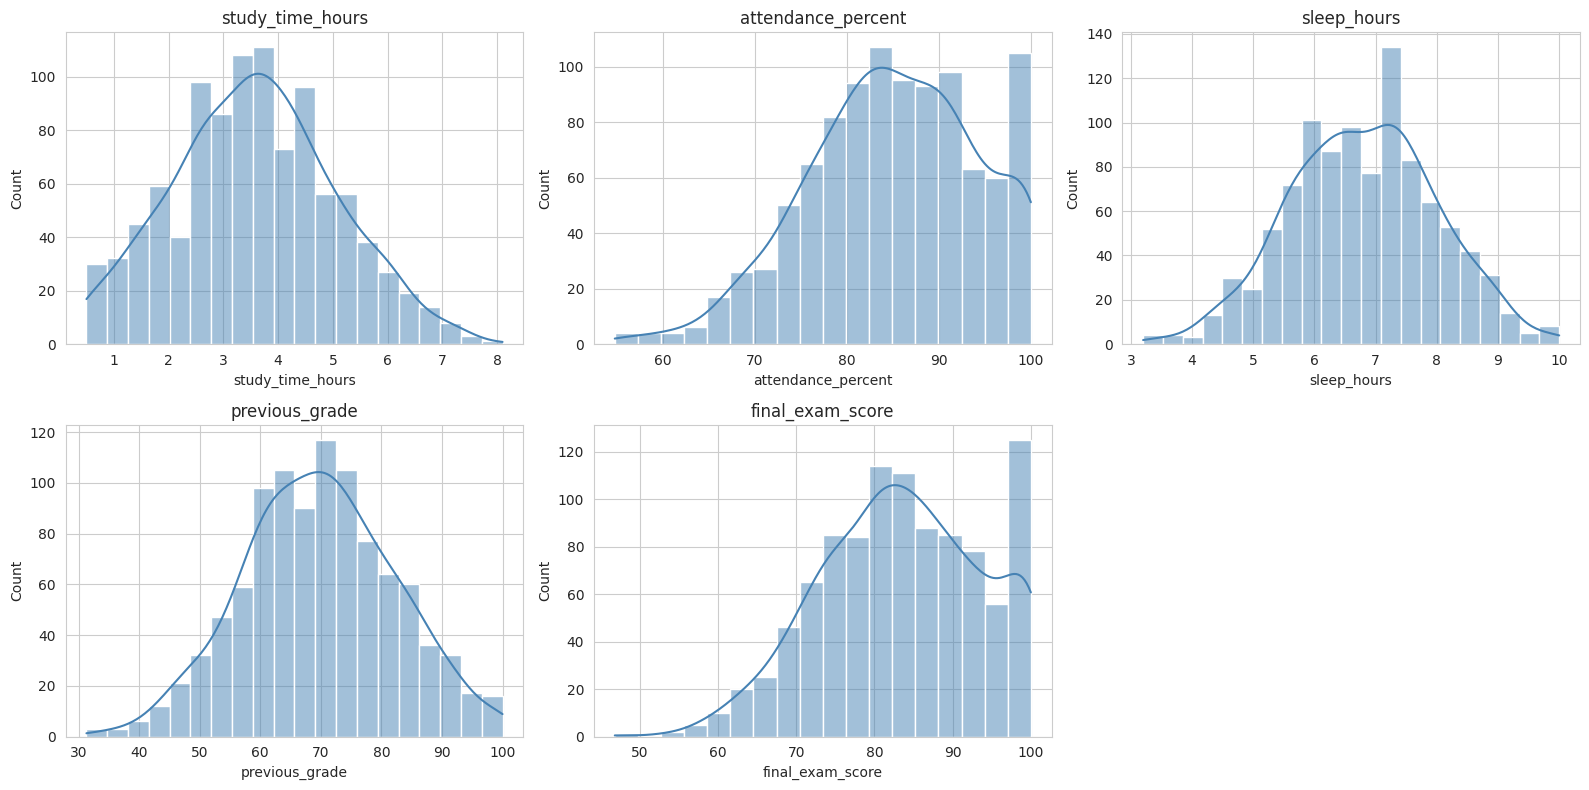

In [9]:
numeric_cols = ["study_time_hours", "attendance_percent", "sleep_hours", "previous_grade", "final_exam_score"]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.histplot(df[col], kde=True, ax=ax, color="steelblue")
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

### 3.3 Coorelation between numeric features

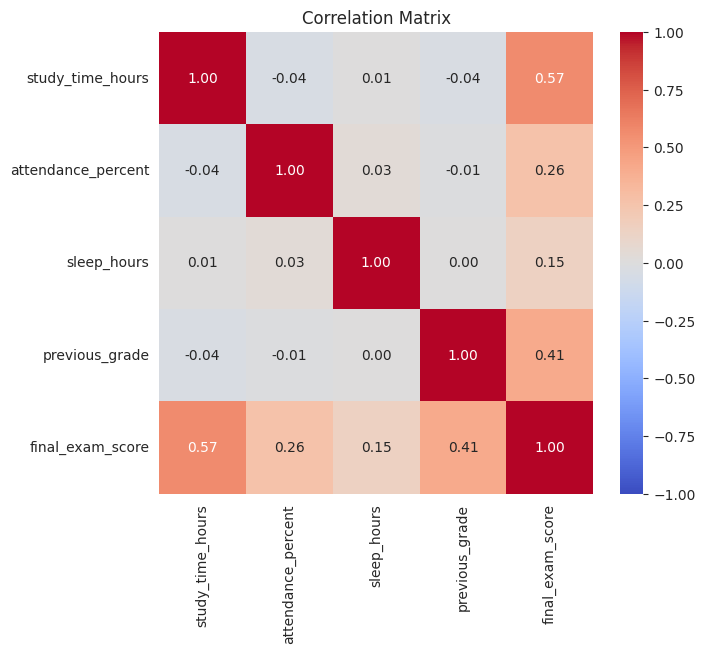

In [10]:
corr = df[numeric_cols].corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix")
plt.show()

`final_exam_score` and `previous_grade` are the two variables most tightly linked to
final grade by construction worth checking whether study/attendance/sleep add
predictive signal beyond them, or mostly act through them.

### 3.4 Numeric features vs final grade

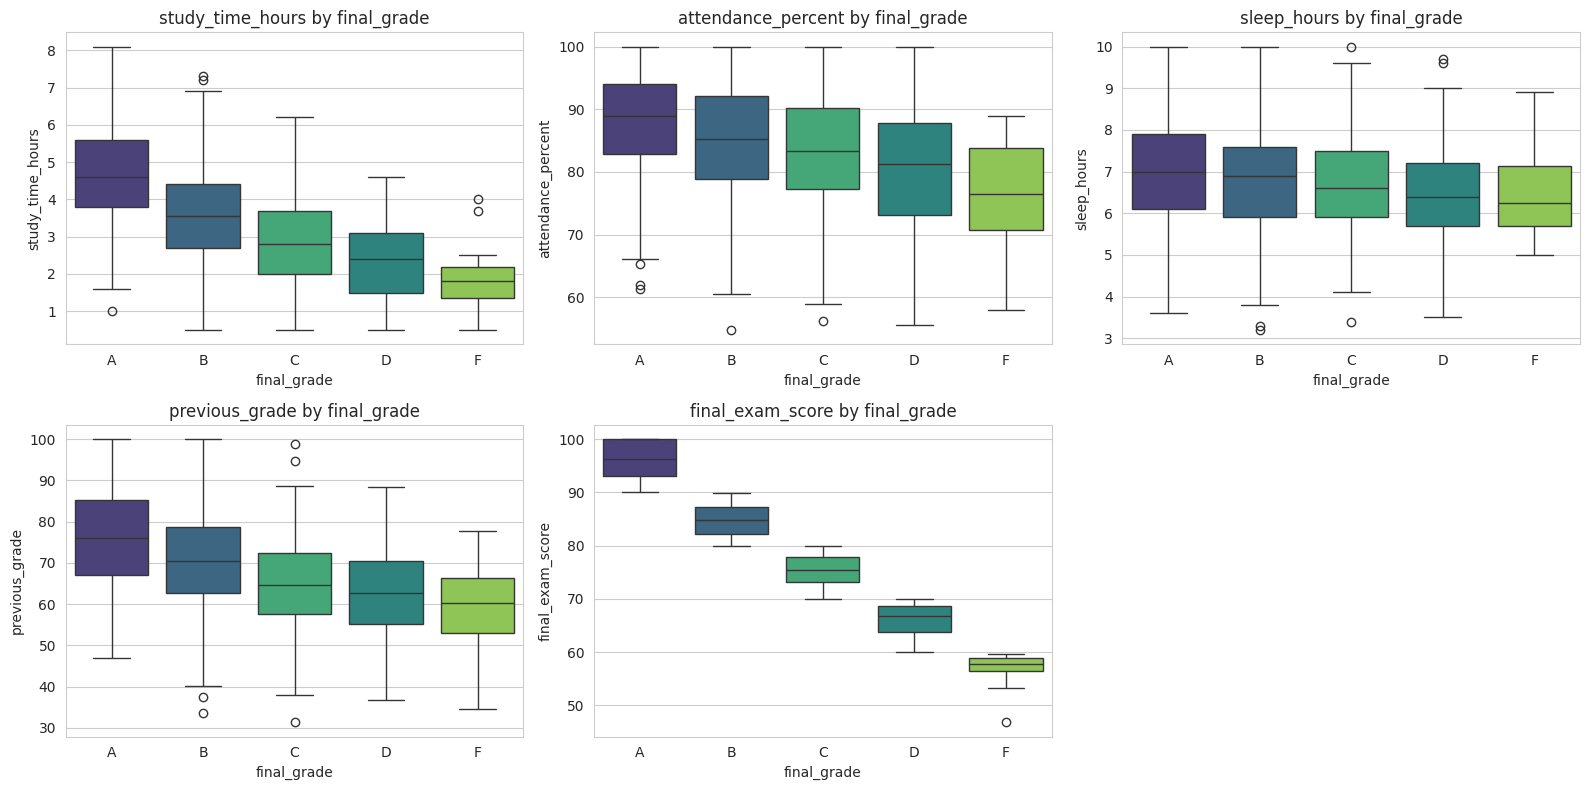

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.flat, numeric_cols):
    sns.boxplot(
        data=df, 
        x="final_grade", 
        y=col, 
        hue="final_grade", 
        legend=False, 
        order=order, 
        ax=ax, 
        palette="viridis"
    )
    ax.set_title(f"{col} by final_grade")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

### 3.5 Categorical features vs. final grade

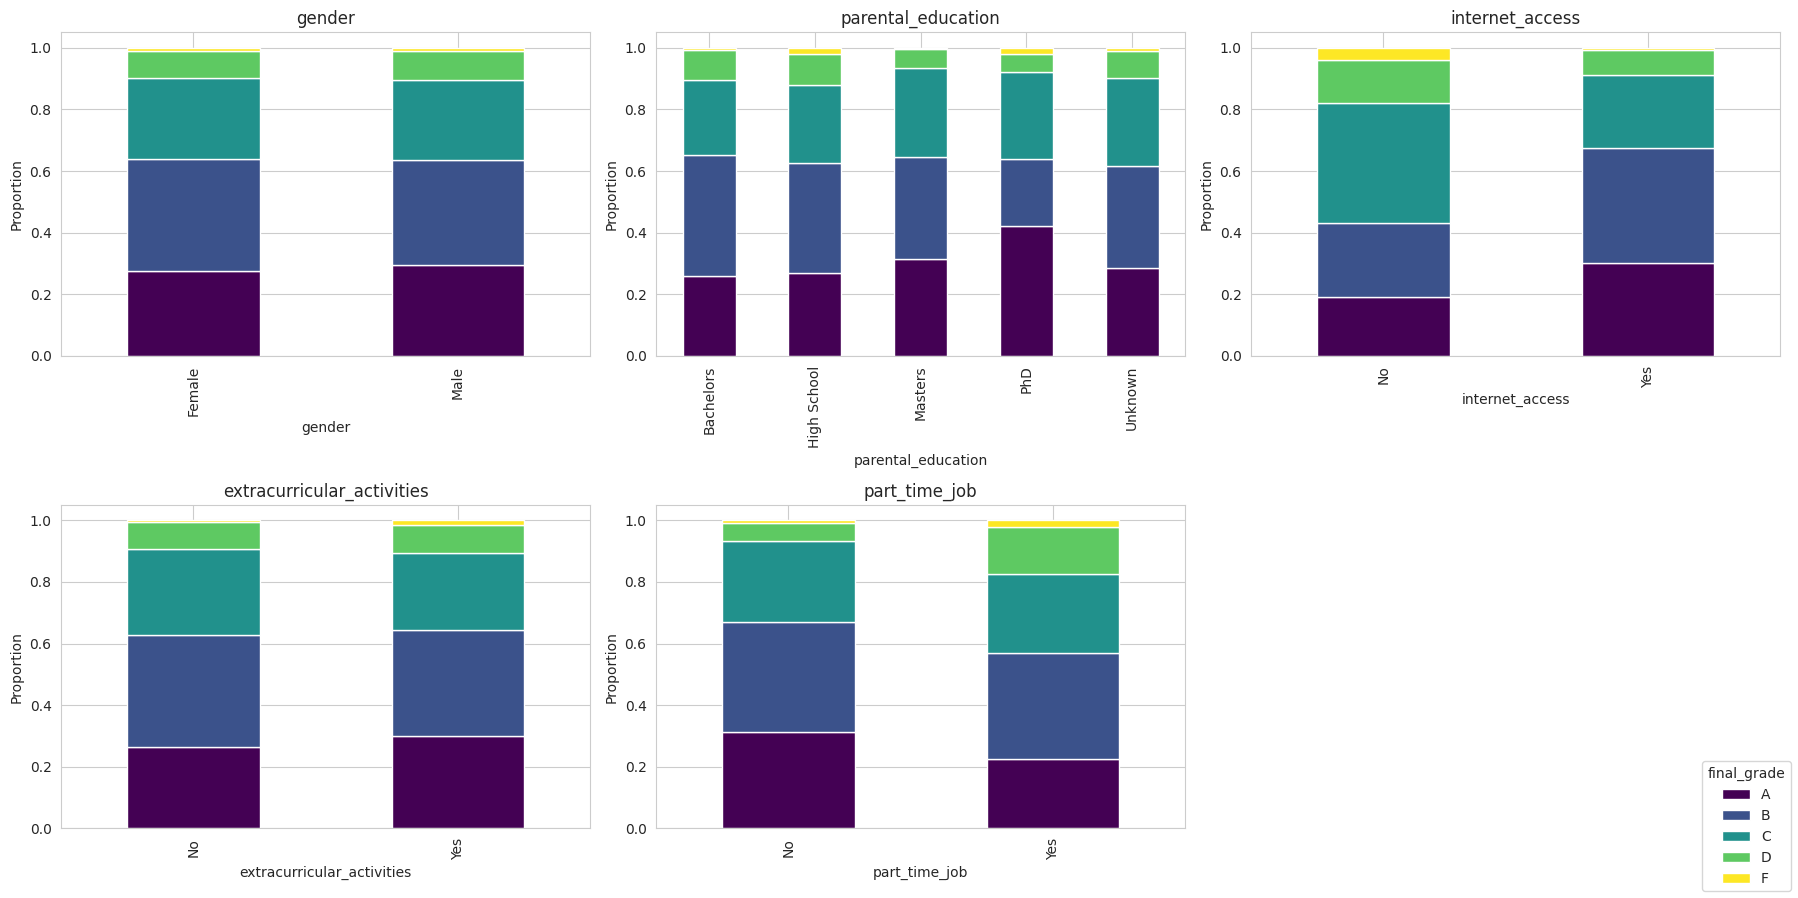

In [12]:
cat_cols = ["gender", "parental_education", "internet_access", "extracurricular_activities", "part_time_job"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, cat_cols):
    ct = pd.crosstab(df[col], df["final_grade"], normalize="index")[order]
    ct.plot(kind="bar", stacked=True, ax=ax, colormap="viridis", legend=False)
    ax.set_title(col)
    ax.set_ylabel("Proportion")
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, title="final_grade", loc="lower right")
plt.tight_layout()
plt.show()

**Takeaways so far:**
- Attendance and study time show a visible positive relationship with grade.
- Sleep hours show a milder relationship likely present but weaker.
- `previous_grade` and `final_exam_score` are strong signals, as expected.
- Categorical features (internet access, extracurriculars, part-time job, parental
  education) don't show dramatic separation on their own, they may still help in
  combination with other features.

# 4. Feature engineering and preprocessing

In [13]:
feature_cols = [c for c in df.columns if c not in ["student_id", "final_grade"]]
X = df[feature_cols].copy()
y = df["final_grade"].copy()

numeric_features = ["study_time_hours", "attendance_percent", "sleep_hours",
                     "previous_grade", "final_exam_score"]
categorical_features = ["gender", "parental_education", "internet_access",
                         "extracurricular_activities", "part_time_job"]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features),
])

In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)
print(X_train.shape, X_test.shape)

(800, 10) (200, 10)


# 5. Modeling

We'll compare a simple linear baseline (logistic regression) against a random forest,
using cross-validated macro-F1 (fairer than accuracy given the class imbalance).

In [15]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE, n_estimators=300),
}

for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring="f1_macro")
    print(f"{name}: macro-F1 = {scores.mean():.3f} (+/- {scores.std():.3f})")

Logistic Regression: macro-F1 = 0.759 (+/- 0.061)
Random Forest: macro-F1 = 0.763 (+/- 0.008)


### 5.1 Hyperparameter tuning (Random Forest)

In [16]:
rf_pipe = Pipeline([("prep", preprocessor), ("model", RandomForestClassifier(random_state=RANDOM_STATE))])

param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [None, 8, 12],
    "model__min_samples_leaf": [1, 2, 4],
}

grid = GridSearchCV(rf_pipe, param_grid, cv=5, scoring="f1_macro", n_jobs=-1)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV macro-F1:", grid.best_score_)

best_model = grid.best_estimator_

Best params: {'model__max_depth': 12, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}
Best CV macro-F1: 0.7641501685729237


# 6. Evaluation on Test Set

In [17]:
y_pred = best_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Macro F1:", f1_score(y_test, y_pred, average="macro", zero_division=0))
print()
print(classification_report(y_test, y_pred, labels=order, zero_division=0))

Accuracy: 0.98
Macro F1: 0.7828106289559218

              precision    recall  f1-score   support

           A       1.00      1.00      1.00        57
           B       0.99      0.99      0.99        71
           C       0.98      0.98      0.98        52
           D       0.90      1.00      0.95        18
           F       0.00      0.00      0.00         2

    accuracy                           0.98       200
   macro avg       0.77      0.79      0.78       200
weighted avg       0.97      0.98      0.98       200



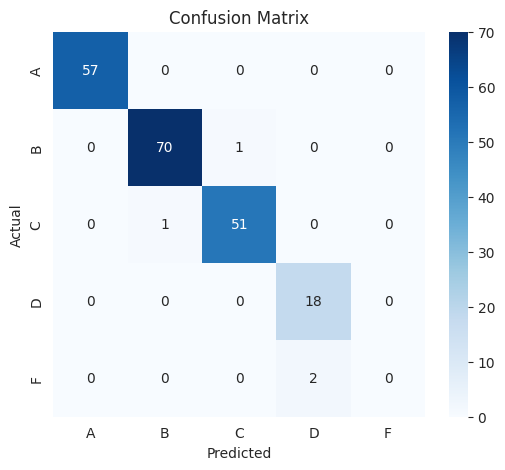

In [18]:
cm = confusion_matrix(y_test, y_pred, labels=order)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=order, yticklabels=order)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

### 6.1 Feature importance

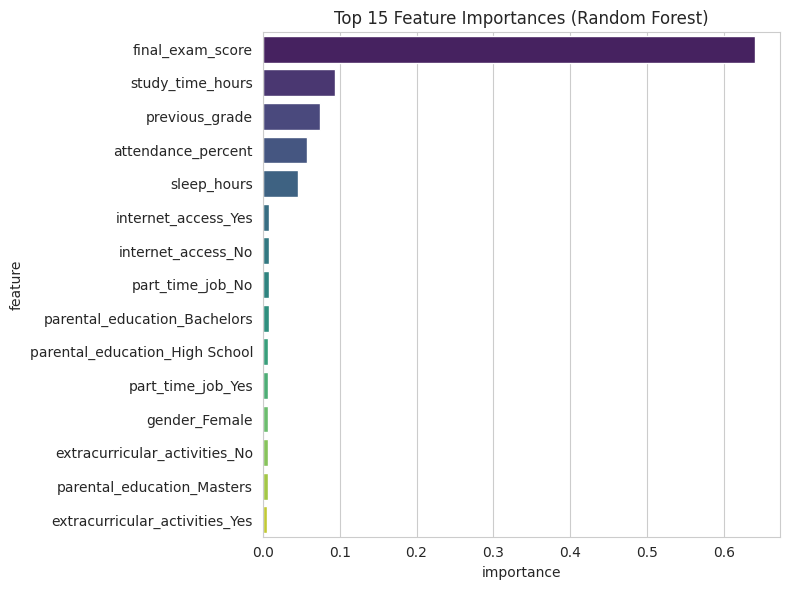

In [19]:
ohe_cols = best_model.named_steps["prep"].named_transformers_["cat"].get_feature_names_out(categorical_features)
all_feature_names = numeric_features + list(ohe_cols)

importances = best_model.named_steps["model"].feature_importances_
imp_df = pd.DataFrame({"feature": all_feature_names, "importance": importances}) \
    .sort_values("importance", ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(
    data=imp_df, 
    y="feature", 
    x="importance", 
    hue="feature", 
    legend=False, 
    palette="viridis"
)
plt.title("Top 15 Feature Importances (Random Forest)")
plt.tight_layout()
plt.show()

# 7. Conclusion & Next Steps

**Summary**
- The tuned Random Forest outperformed the logistic regression baseline on macro-F1,
  reflecting its ability to capture non-linear interactions between features.
- `final_exam_score` and `previous_grade` dominate feature importance, which makes
  sense given how grades are typically computed but `attendance_percent` and
  `study_time_hours` still contribute meaningfully, confirming they matter beyond
  just correlating with exam performance.
- The minority classes (`D`, `F`) remain the hardest to predict reliably, which is
  expected given how few examples exist for them.

**Possible next steps**
- Try class-weighting or resampling (e.g. SMOTE) to improve recall on `D`/`F`.
- Engineer interaction features (e.g. study_time × attendance).
- Try gradient boosting models (XGBoost/LightGBM) for a potential accuracy lift.
- If the goal is early intervention rather than final prediction, refit the model
  using only features known *before* the final exam (drop `final_exam_score`) to
  see how predictive study habits alone are.

Thanks for following along, feel free to fork this notebook and try the extensions above.
